# Publication figures and tables — ZTF 8-year kilonova rate limits

Every figure and number in this notebook is computed from the results snapshot chosen in the settings cell
(see `knrates/collect.py`). Figures are written to `paper/figures/` (PDF + PNG) and the summary table to
`paper/table1_master_rate_limits.{csv,tex}`.

**Status of inputs** (see the review report for details):
* Suite 01 and Suite 07 (fixed-parameter ensembles, $100\times10^6$ injections each) — correctly analysed, but the
  survey_sim version used over-matches pointings (⟨VT⟩ ≈ 30 % too high) and double-dilates Bu2026 light curves
  (+4 %); **all limits must be regenerated after the engine fix** (re-run, rebuild the snapshot, re-execute).
* Suite 02 (criteria sweep) — known bugs (Galactic-latitude cut not applied, VT normalisation, fiducial point does not
  reproduce Suite 01); Figure 6 is shown for development only and must be regenerated after the re-run.
* Former Figure 4 ("archetype optimism bias") and Figure 7 (imposter purity/colour curves) had no simulation
  input and are not produced. Former Suite 05/06 numbers are replaced by analyses of the real realisations.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"     # "latest" | time stamp or prefix (e.g. "20261109") | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = True     # write PDF+PNG copies of every figure to FIG_DIR
FIG_DIR = "paper/figures"
# ---------------------------------------------------------------------------
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from knrates import load_snapshot, list_snapshots
from knrates import analysis as A, literature as L, plotting as P
from knrates.stats import LN20, rate_upper_limit, summarize_runs

P.use_style("paper")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", "{:.4g}".format)
snap = load_snapshot(SNAPSHOT)
print(snap.describe())
print("\nAvailable snapshots:", [p.name for p in list_snapshots()])

def save(fig, name):
    if SAVE_FIGURES:
        for p in P.savefig(fig, name, ROOT / FIG_DIR):
            print("saved", p.relative_to(ROOT))

Snapshot: knrates_results_latest.zip (created 20261109T184311Z, git 3fe520af)
  suite01_runs                       300 rows
  suite01_sources                 76,976 rows
  suite01_texp_month                 291 rows
  suite01_z_hist                     360 rows
  suite02_candidate_runs             300 rows
  suite02_fiducial                     3 rows
  suite02_grid_marginals             156 rows
  suite02_grid_size                    3 rows
  suite02_slices_1d                  147 rows
  suite02_slices_2d                3,153 rows
  suite03_runs                        36 rows
  suite07_runs                       400 rows
  suite07_sources                254,591 rows
  suite07_texp_month                 388 rows
  suite07_z_hist                     480 rows

Available snapshots: ['knrates_results_latest.zip']


In [2]:
runs = pd.concat([snap["suite01_runs"], snap.get("suite07_runs", pd.DataFrame())], ignore_index=True)
tm = pd.concat([snap["suite01_texp_month"], snap.get("suite07_texp_month", pd.DataFrame())], ignore_index=True)
zh = pd.concat([snap["suite01_z_hist"], snap.get("suite07_z_hist", pd.DataFrame())], ignore_index=True)
src = pd.concat([snap["suite01_sources"], snap.get("suite07_sources", pd.DataFrame())], ignore_index=True)
ALL = [m for m in P.MODEL_STYLE if m in set(runs.model)]
lim = A.headline_limits(runs, ALL)
L_ = lim.set_index("model")
display(lim[["model", "n_runs", "n_detected", "efficiency", "vt_gpc3_yr", "r90", "r95", "r95_err_mc", "r99"]])

,model,n_runs,n_detected,efficiency,vt_gpc3_yr,r90,r95,r95_err_mc,r99
0,Bu2026Fixed,100,184316,0.001843,0.0156,147.6,192,0.4394,295.2
1,Bu2026Vary,100,53948,0.0005395,0.004515,510,663.6,2.973,1020
2,Metzger,100,47831,0.0004783,0.003963,581,755.8,3.547,1162
3,GW170817_Bu2026_FixedView,100,186028,0.00186,0.01572,146.5,190.6,0.4026,293
4,GW170817_Bu2026_Isotropic,100,57435,0.0005743,0.004804,479.3,623.6,2.363,958.7
5,GW170817_Metzger_Blue,100,1316108,0.01316,0.1105,20.84,27.12,0.02331,41.69
6,GW170817_Metzger_Mean,100,468311,0.004683,0.03977,57.9,75.33,0.1024,115.8


## Figure 1 — Sensitivity accumulated over the ZTF survey

saved paper/figures/fig1_survey_volume_timeline.pdf
saved paper/figures/fig1_survey_volume_timeline.png


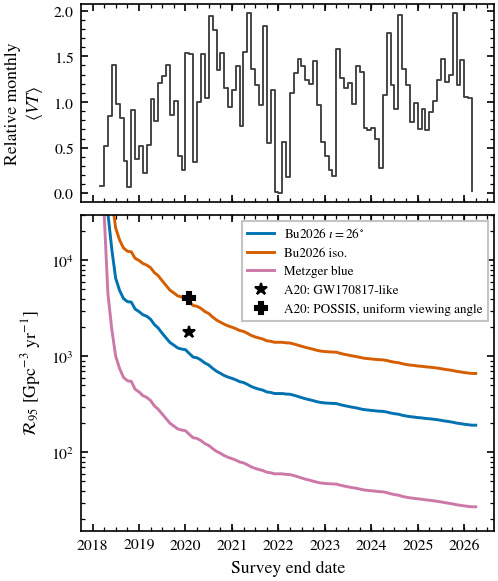

In [3]:
MAIN = [m for m in ["Bu2026Fixed", "Bu2026Vary", "GW170817_Metzger_Blue"] if m in ALL]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(P.COL_WIDTH, 3.9), sharex=True, height_ratios=[1, 1.6])
e0 = A.vt_by_epoch(tm, runs, MAIN[0])
ax1.step(e0["month"].dt.to_timestamp(), e0["vt_month"] / e0["vt_month"].mean(), where="post", color="0.25", lw=0.9)
ax1.set_ylabel("Relative monthly\n" + r"$\langle VT\rangle$")
for m in MAIN:
    e = A.vt_by_epoch(tm, runs, m); e = e[e.vt_cumulative > 0]
    ax2.plot(e["month_end"], e["r95_cumulative"], color=P.style(m)["color"], label=P.SHORT_LABEL[m])
win_end = pd.Period("2020-01", "M").to_timestamp(how="end")
for key, mk in [("andreoni20_gw170817", "*"), ("andreoni20_possis_iso", "P")]:
    r = L.lookup(key); ax2.plot(win_end, r["limit"], mk, color="k", ms=6, label=f"A20: {r['model']}")
ax2.set_yscale("log"); ax2.set_ylim(15, 3e4)
ax2.set_ylabel(P.RATE_LABEL); ax2.set_xlabel("Survey end date")
ax2.legend(loc="upper right", fontsize=6.3)
save(fig, "fig1_survey_volume_timeline"); plt.show()

## Figure 2 — Viewing-angle dependence (from the isotropic ensembles)

saved paper/figures/fig2_inclination_anatomy.pdf
saved paper/figures/fig2_inclination_anatomy.png


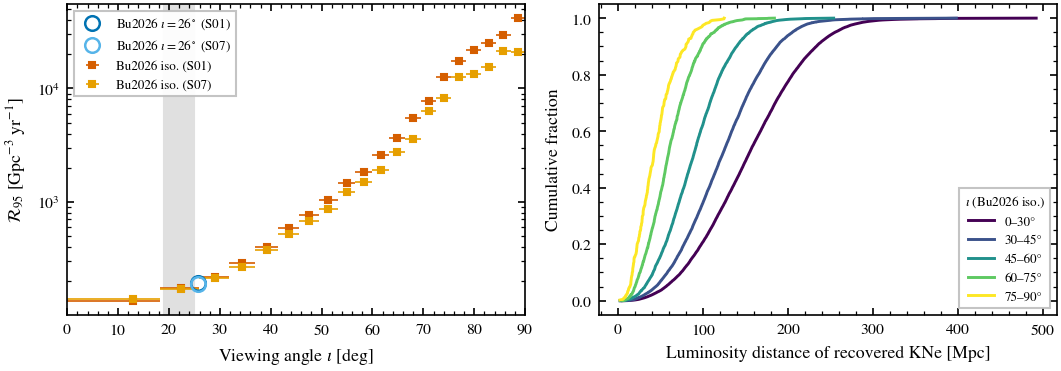

In [4]:
ISO = [m for m in ["Bu2026Vary", "GW170817_Bu2026_Isotropic"] if m in ALL]
inc = {m: A.inclination_efficiency(src, runs, m, n_bins=20) for m in ISO}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(P.PAGE_WIDTH, 2.5))
for m, t in inc.items():
    st = P.style(m)
    xerr = [t.iota_deg_center - t.iota_deg_lo, t.iota_deg_hi - t.iota_deg_center]
    ax1.errorbar(t.iota_deg_center, t.r95, xerr=xerr, fmt=st["marker"], color=st["color"], ms=3, lw=0.8,
                 label=P.SHORT_LABEL[m] + (" (S01)" if m == "Bu2026Vary" else " (S07)"))
for f in ["Bu2026Fixed", "GW170817_Bu2026_FixedView"]:
    if f in L_.index:
        st = P.style(f)
        ax1.plot(np.degrees(0.45), L_.loc[f, "r95"], st["marker"], mfc="none", mec=st["color"], ms=7, mew=1.2,
                 label=P.SHORT_LABEL[f] + (" (S01)" if f == "Bu2026Fixed" else " (S07)"))
lo, hi = L.AT2017GFO["viewing_angle_deg"]
ax1.axvspan(lo, hi, color="0.88", zorder=0)
ax1.set_yscale("log"); ax1.set_xlim(0, 90); ax1.set_xlabel(r"Viewing angle $\iota$ [deg]"); ax1.set_ylabel(P.RATE_LABEL)
ax1.legend(loc="upper left", fontsize=6.3)
m0 = ISO[0]; s = src[src.model == m0]
edges = np.radians([0, 30, 45, 60, 75, 90]); cmap = plt.get_cmap("viridis")
for i in range(len(edges) - 1):
    sel = s[(s.inclination_rad >= edges[i]) & (s.inclination_rad < edges[i + 1])]
    d = np.sort(A.luminosity_distance_mpc(sel.z.to_numpy()))
    ax2.plot(d, np.arange(1, len(d) + 1) / len(d), color=cmap(i / (len(edges) - 2)),
             label=f"{np.degrees(edges[i]):.0f}–{np.degrees(edges[i+1]):.0f}°")
ax2.set_xlabel("Luminosity distance of recovered KNe [Mpc]"); ax2.set_ylabel("Cumulative fraction")
ax2.legend(loc="lower right", fontsize=6.3, title=r"$\iota$ (" + P.SHORT_LABEL[m0] + ")", title_fontsize=6.3)
save(fig, "fig2_inclination_anatomy"); plt.show()

## Figure 3 — Rate limits compared with previous searches and the GW BNS rate

/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)


saved paper/figures/fig3_rate_limits_master.pdf
saved paper/figures/fig3_rate_limits_master.png


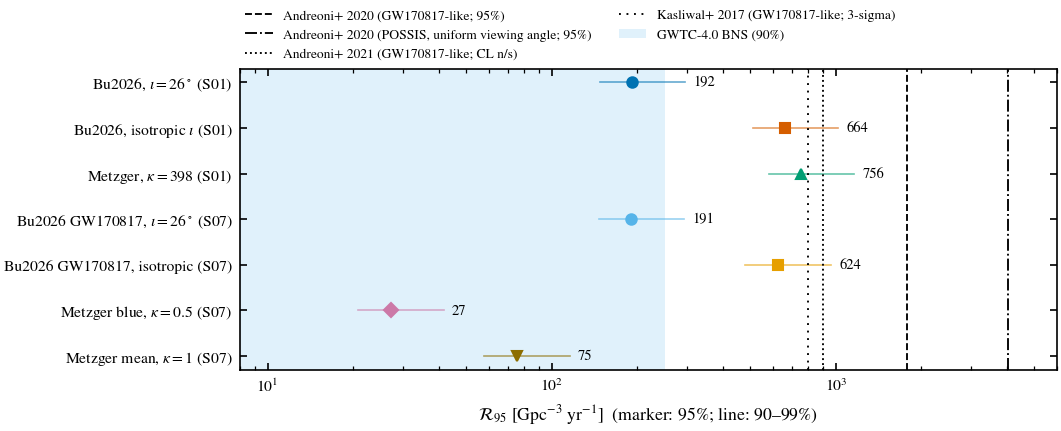

In [5]:
fig, ax = plt.subplots(figsize=(P.PAGE_WIDTH, 2.9))
rows = list(L_.loc[ALL].iterrows())
y = np.arange(len(rows))[::-1]
for yi, (m, r) in zip(y, rows):
    st = P.style(m)
    ax.errorbar(r.r95, yi, xerr=r.r95_err_mc, fmt=st["marker"], color=st["color"], ms=5)
    ax.plot([r.r90, r.r99], [yi, yi], color=st["color"], lw=0.8, alpha=0.6)
    ax.annotate(f"{r.r95:.0f}", (r.r99, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7)
lit = L.rate_limits_table()
lit = lit[lit.key.isin(["andreoni20_gw170817", "andreoni20_possis_iso", "andreoni21_ztfrest_combined", "kasliwal17_ptf"])]
ls = {"andreoni20_gw170817": "--", "andreoni20_possis_iso": "-.", "andreoni21_ztfrest_combined": ":", "kasliwal17_ptf": (0, (1, 3))}
for _, r in lit.iterrows():
    cl = "CL n/s" if r.cl.startswith("not stated") else r.cl.replace(" (implied)", "")
    ax.axvline(r.limit, color="k", ls=ls[r.key], lw=0.9, label=f"{r.ref.replace(' et al.', '+')} ({r.model}; {cl})")
for g in L.GW_BNS_RATES:
    if g["key"] == "gwtc4":
        ax.axvspan(g["low"], g["high"], color=P.OKABE_ITO["skyblue"], alpha=0.18, lw=0, label="GWTC-4.0 BNS (90%)")
ax.set_yticks(y, [P.style(m)["label"] for m, _ in rows])
ax.set_xscale("log"); ax.set_xlim(8, 6e3); ax.set_xlabel(P.RATE_LABEL + r"  (marker: 95%; line: 90–99%)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False, fontsize=6.5, borderaxespad=0)
save(fig, "fig3_rate_limits_master"); plt.show()

## Figure 4 — Distance reach of each model

saved paper/figures/fig4_recovery_distance.pdf
saved paper/figures/fig4_recovery_distance.png


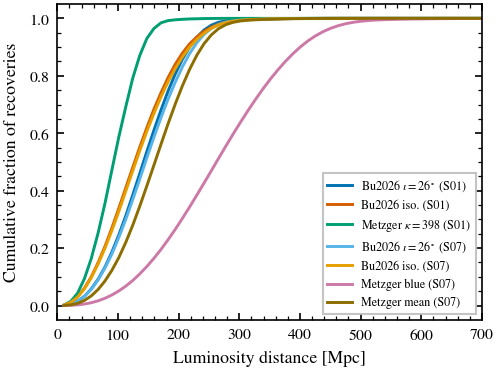

In [6]:
fig, ax = plt.subplots(figsize=(P.COL_WIDTH, 2.5))
for m in ALL:
    h = zh[zh.model == m].groupby(["z_lo", "z_hi"], as_index=False)["n_detected"].sum().sort_values("z_lo")
    c = np.cumsum(h.n_detected) / h.n_detected.sum()
    ax.plot(A.luminosity_distance_mpc(h.z_hi.to_numpy()), c, color=P.style(m)["color"], label=P.SHORT_LABEL[m]
            + (" (S07)" if m.startswith("GW") else " (S01)"))
ax.set_xlim(0, 700); ax.set_xlabel("Luminosity distance [Mpc]"); ax.set_ylabel("Cumulative fraction of recoveries")
ax.legend(loc="lower right", fontsize=5.8)
save(fig, "fig4_recovery_distance"); plt.show()

## Figure 5 — Monte Carlo convergence from real realisations

saved paper/figures/fig5_convergence_and_catastrophe.pdf
saved paper/figures/fig5_convergence_and_catastrophe.png


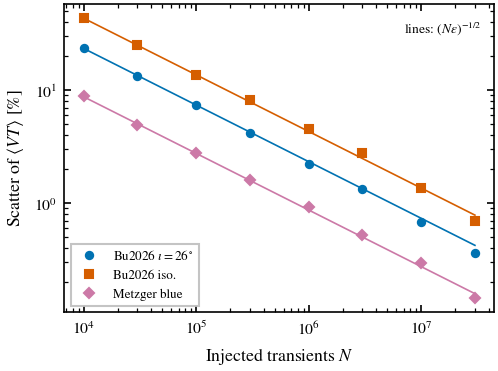

,model,n_injected,mean_k,p_zero_empirical,rel_scatter_vt,rel_err_binomial
0,Bu2026Fixed,10000,18.43,0,0.2348,0.2329
1,Bu2026Fixed,30000,55.3,0,0.1326,0.1345
2,Bu2026Fixed,100000,184.6,0,0.07318,0.07366
3,Bu2026Fixed,300000,552.5,0,0.04203,0.04253
4,Bu2026Fixed,1000000,1843,0,0.02242,0.02329
5,Bu2026Fixed,3000000,5529,0,0.01349,0.01345
6,Bu2026Fixed,10000000,1.843e+04,0,0.006879,0.007366
7,Bu2026Fixed,30000000,5.53e+04,0,0.003619,0.004253
8,Bu2026Vary,10000,5.392,0.004333,0.4323,0.4305
9,Bu2026Vary,30000,16.14,0,0.2506,0.2486


In [7]:
SIZES = [10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000]
CM = [m for m in ["Bu2026Fixed", "Bu2026Vary", "GW170817_Metzger_Blue"] if m in ALL]
conv = pd.concat([A.subsampling_convergence(runs, m, SIZES, 3000) for m in CM], ignore_index=True)
fig, ax = plt.subplots(figsize=(P.COL_WIDTH, 2.5))
for m in CM:
    c = conv[conv.model == m]; st = P.style(m)
    ax.plot(c.n_injected, 100 * c.rel_scatter_vt, st["marker"], color=st["color"], ms=3.5, label=P.SHORT_LABEL[m])
    ax.plot(c.n_injected, 100 * c.rel_err_binomial, "-", color=st["color"], lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Injected transients $N$"); ax.set_ylabel(r"Scatter of $\langle VT\rangle$ [%]")
ax.legend(loc="lower left", fontsize=6.3)
ax.text(0.97, 0.95, r"lines: $(N\epsilon)^{-1/2}$", transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
save(fig, "fig5_convergence_and_catastrophe"); plt.show()
display(conv[["model", "n_injected", "mean_k", "p_zero_empirical", "rel_scatter_vt", "rel_err_binomial"]])

## Figure 6 — Criteria sensitivity (Suite 02; DEVELOPMENT ONLY until Suite 02 is re-run)

saved paper/figures/fig6_criteria_sensitivity_PRELIMINARY.pdf
saved paper/figures/fig6_criteria_sensitivity_PRELIMINARY.png


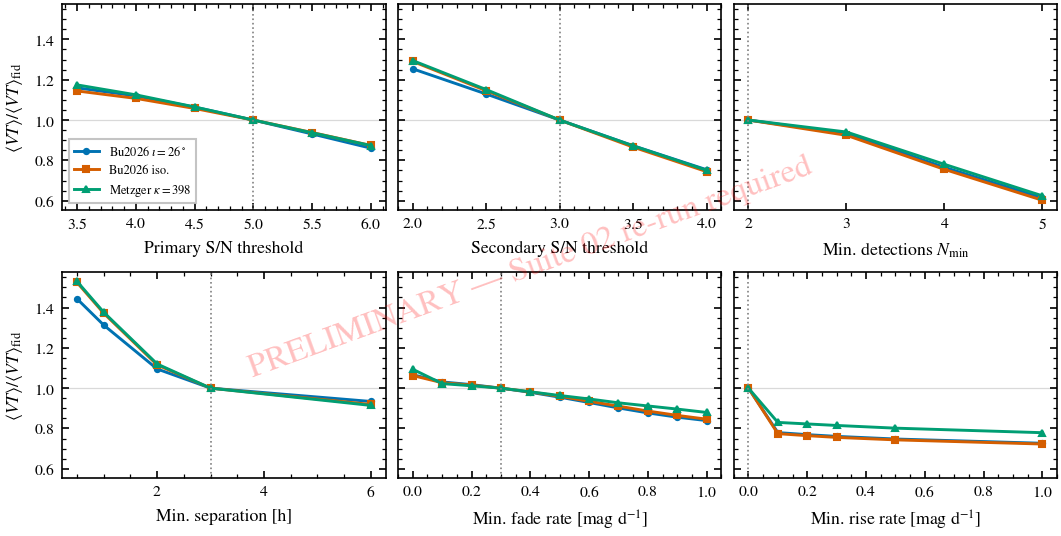

In [8]:
if "suite02_slices_1d" in snap:
    s1 = snap["suite02_slices_1d"]; fid = snap["suite02_fiducial"].set_index("model")
    FID = dict(snr_threshold=5.0, snr_threshold_secondary=3.0, min_detections=2, min_time_separation_hours=3.0,
               min_fade_rate=0.3, min_rise_rate=0.0)
    fig, axes = plt.subplots(2, 3, figsize=(P.PAGE_WIDTH, 3.6), sharey=True)
    for ax, c in zip(axes.flat, FID):
        for m in fid.index:
            d = s1[(s1.varied == c) & (s1.model == m)].sort_values(c); st = P.style(m)
            ax.plot(d[c], d.effective_vt_gpc3_yr / fid.loc[m, "effective_vt_gpc3_yr"], marker=st["marker"], ms=2.5,
                    color=st["color"], label=P.SHORT_LABEL[m])
        ax.axvline(FID[c], color="0.5", ls=":", lw=0.8); ax.axhline(1, color="0.85", lw=0.6, zorder=0)
        ax.set_xlabel(P.CRITERION_LABEL[c])
        if c == "min_detections":
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.xaxis.set_minor_locator(plt.NullLocator())
    for ax in axes[:, 0]:
        ax.set_ylabel(r"$\langle VT\rangle/\langle VT\rangle_{\rm fid}$")
    axes.flat[0].legend(loc="lower left", fontsize=6)
    fig.text(0.5, 0.5, "PRELIMINARY — Suite 02 re-run required", fontsize=16, color="red", alpha=0.25,
             ha="center", va="center", rotation=20)
    save(fig, "fig6_criteria_sensitivity_PRELIMINARY"); plt.show()

## Table 1 — Rate limits

In [9]:
import json
def _desc(m):
    p = json.loads(runs.loc[runs.model == m, "params_json"].iloc[0])
    p = {k.lower(): v for k, v in p.items()}
    if "kappa" in p:
        return f"$M_{{\\rm ej}}={p['mej']:g}\\,M_\\odot$, $v={p['vej']:g}c$, $\\kappa={p['kappa']:g}$"
    inc = p.get("inclination_em")
    inc_s = "isotropic" if (p.get("vary_inclination") is True or inc == "varied") else f"$\\iota={np.degrees(float(inc)):.1f}^\\circ$"
    return (f"$\\log M_{{\\rm dyn}}={p['log10_mej_dyn']:g}$, $\\log M_{{\\rm wind}}={p['log10_mej_wind']:g}$, {inc_s}")
tab = lim[["model", "n_simulated", "n_detected", "vt_gpc3_yr", "vt_err_empirical", "r90", "r95", "r99"]].copy()
tab.insert(1, "suite", np.where(tab.model.str.startswith("GW170817"), "07", "01"))
tab.insert(2, "parameters", [_desc(m) for m in tab.model])
out = ROOT / "paper"
tab.to_csv(out / "table1_master_rate_limits.csv", index=False)
tex = tab.assign(vt=lambda d: [f"{v*1e3:.2f} $\\pm$ {e*1e3:.2f}" for v, e in zip(d.vt_gpc3_yr, d.vt_err_empirical)])
tex = tex[["model", "suite", "parameters", "n_detected", "vt", "r90", "r95", "r99"]]
tex.columns = ["Model", "Suite", "Parameters", "$N_{\\rm rec}$", "$\\langle VT\\rangle$ [$10^{-3}$ Gpc$^3$ yr]",
               "$\\mathcal{R}_{90}$", "$\\mathcal{R}_{95}$", "$\\mathcal{R}_{99}$"]
tex["Model"] = tex["Model"].str.replace("_", "\\_")
(out / "table1_master_rate_limits.tex").write_text(
    tex.to_latex(index=False, escape=False, float_format="%.0f", column_format="lllrrrrr"))
print("wrote", out / "table1_master_rate_limits.csv", "and .tex"); display(tex)

wrote /Users/tbarna/Documents/GitHub/kn-rates/paper/table1_master_rate_limits.csv and .tex


,Model,Suite,Parameters,$N_{\rm rec}$,$\langle VT\rangle$ [$10^{-3}$ Gpc$^3$ yr],$\mathcal{R}_{90}$,$\mathcal{R}_{95}$,$\mathcal{R}_{99}$
0,Bu2026Fixed,01,"$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",184316,15.60 $\pm$ 0.04,147.6,192,295.2
1,Bu2026Vary,01,"$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",53948,4.51 $\pm$ 0.02,510,663.6,1020
2,Metzger,01,"$M_{\rm ej}=0.00126\,M_\odot$, $v=0.5c$, $\kap...",47831,3.96 $\pm$ 0.02,581,755.8,1162
3,GW170817\_Bu2026\_FixedView,07,"$\log M_{\rm dyn}=-1.8$, $\log M_{\rm wind}=-1...",186028,15.72 $\pm$ 0.03,146.5,190.6,293
4,GW170817\_Bu2026\_Isotropic,07,"$\log M_{\rm dyn}=-1.8$, $\log M_{\rm wind}=-1...",57435,4.80 $\pm$ 0.02,479.3,623.6,958.7
5,GW170817\_Metzger\_Blue,07,"$M_{\rm ej}=0.02\,M_\odot$, $v=0.25c$, $\kappa...",1316108,110.47 $\pm$ 0.09,20.84,27.12,41.69
6,GW170817\_Metzger\_Mean,07,"$M_{\rm ej}=0.04\,M_\odot$, $v=0.15c$, $\kappa=1$",468311,39.77 $\pm$ 0.05,57.9,75.33,115.8
